# 1. The data: what the file can and cannot answer

**Transplant or Wait** · Aya Bekhtiar, Apolline Hadjal · Applied AI for Health 2026–2027

The department asked for a tool to decide, at diagnosis, between transplanting a patient with myelodysplastic syndrome (MDS) now or waiting. Before any model, this notebook interrogates the file against that purpose:

1. What the two files contain, and what they do not
2. Turning free-text karyotypes into IPSS-R risk groups
3. Who is in scope: the cohort flow
4. Follow-up and censoring: why every proportion is a Kaplan–Meier estimate
5. Missing inputs at the time of decision
6. Centres differ more than their case mix explains
7. The reference scores IPSS-R and IPSS-M, and the overlap with the IPSS-M development cohort

Every number in the report's data section comes from this notebook. It saves the report's figures F1–F4 to `outputs/figures/` and the tables to `outputs/tables/` and `outputs/audit.json`.

In [1]:
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
sys.path.insert(0, ROOT)
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from mds_tool import HORIZON_YEARS, cohort, metrics, plotting, scores
plotting.setup()
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)
H = HORIZON_YEARS  # 2-year horizon

import json
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/tables", exist_ok=True)
FIG, TAB = "outputs/figures", "outputs/tables"

## 1. The two files

`df_clinical_train.tsv` has one row per patient: centre, marrow blast %, blood counts, a free-text karyotype and overall survival (`OS_YEARS`, `OS_STATUS` = 1 if dead). `mut_clinical_train.tsv` has one row per mutation found by the sequencing panel.

In [2]:
clin = pd.read_csv("df_clinical_train.tsv", sep="\t")
muts = pd.read_csv("mut_clinical_train.tsv", sep="\t")
print(f"clinical: {clin.shape[0]} patients x {clin.shape[1]} columns")
print(f"mutations: {muts.shape[0]} rows, {muts.GENE.nunique()} genes, {muts.ID.nunique()} patients with >= 1 mutation")
print(f"centres: {clin.CENTER.nunique()}")
clin.head()

clinical: 3323 patients x 11 columns
mutations: 10935 rows, 124 genes, 3026 patients with >= 1 mutation
centres: 23


,ID,CENTER,BM_BLAST,WBC,ANC,MONOCYTES,HB,PLT,CYTOGENETICS,OS_YEARS,OS_STATUS
0,P132697,MSK,14.0,2.8,0.2,0.7,7.6,119.0,"46,xy,del(20)(q12)[2]/46,xy[18]",1.115068,1.0
1,P132698,MSK,1.0,7.4,2.4,0.1,11.6,42.0,"46,xx",4.928767,0.0
2,P116889,MSK,15.0,3.7,2.1,0.1,14.2,81.0,"46,xy,t(3;3)(q25;q27)[8]/46,xy[12]",2.043836,0.0
3,P132699,MSK,1.0,3.9,1.9,0.1,8.9,77.0,"46,xy,del(3)(q26q27)[15]/46,xy[5]",2.476712,1.0
4,P132700,MSK,6.0,128.0,9.7,0.9,11.1,195.0,"46,xx,t(3;9)(p13;q22)[10]/46,xx[10]",3.145205,0.0


In [3]:
muts.head()

,ID,CHR,START,END,REF,ALT,GENE,PROTEIN_CHANGE,EFFECT,VAF,DEPTH
0,P100000,11,119149248.0,119149248.0,G,A,CBL,p.C419Y,non_synonymous_codon,0.0830,1308.0
1,P100000,5,131822301.0,131822301.0,G,T,IRF1,p.Y164*,stop_gained,0.0220,532.0
2,P100000,3,77694060.0,77694060.0,G,C,ROBO2,p.?,splice_site_variant,0.4100,876.0
3,P100000,4,106164917.0,106164917.0,G,T,TET2,p.R1262L,non_synonymous_codon,0.4300,826.0
4,P100000,2,25468147.0,25468163.0,ACGAAGAGGGGGTGTTC,A,DNMT3A,p.E505fs*141,frameshift_variant,0.0898,942.0


**What the file does not contain**, and why it matters for "transplant or wait":

| Missing | Consequence |
| --- | --- |
| Treatment given, transplant and its date | Survival mixes the natural course with unrecorded treatment: we cannot estimate the *effect* of transplant |
| Age, performance status, comorbidity | Transplant eligibility and transplant-related mortality cannot be modelled |
| Diagnosis label (MDS, AML, CMML) | We approximate MDS with blasts < 20 % and WBC < 13 ×10⁹/L |
| Date of progression to AML | Only overall survival is available |

So the file supports a **prognosis** (risk of death within 2 years under standard care), not a treatment recommendation.

## 2. Free-text karyotypes → IPSS-R cytogenetic groups

The `CYTOGENETICS` column is written by 23 laboratories in ISCN notation (e.g. `46,xy,del(20)(q12)[2]/46,xy[18]`) or shorthand (`complex`, `del5q`). `mds_tool/cytogenetics.py` counts the abnormalities and applies the IPSS-R rules (Schanz et al. 2012). Strings it cannot read are left missing, never guessed.

In [4]:
from mds_tool import cytogenetics as cg

examples = ["46,xy[20]", "45,x,-y[20]", "46,xx,del(5)(q13q33)[12]/46,xx[8]", "47,xy,+8",
            "45,xx,-7[8]/46,xx[15]", "46,xy,inv(3)(q21q26)[20]", "45,xx,del(5)(q13q33),-7,-17,+mar[19]/46,xx[1]",
            "46,xx,asxl-1undrunx-1mutation[13]", "nucish5q31(egr1x2)[100]"]
pd.DataFrame([{"karyotype": k, "abnormalities": cg.parse(k).n_abn, "IPSS-R group": cg.parse(k).category} for k in examples])

,karyotype,abnormalities,IPSS-R group
0,"46,xy[20]",0,Good
1,"45,x,-y[20]",1,Very good
2,"46,xx,del(5)(q13q33)[12]/46,xx[8]",1,Good
3,"47,xy,+8",1,Intermediate
4,"45,xx,-7[8]/46,xx[15]",1,Poor
5,"46,xy,inv(3)(q21q26)[20]",1,Poor
6,"45,xx,del(5)(q13q33),-7,-17,+mar[19]/46,xx[1]",4,Very poor
7,"46,xx,asxl-1undrunx-1mutation[13]",0,Good
8,nucish5q31(egr1x2)[100],0,None


In [5]:
parsed = [cg.parse(x) for x in clin.CYTOGENETICS]
cats = pd.Series([k.category or "missing / unreadable" for k in parsed]).value_counts()
cats.to_frame("patients")

,patients
Good,1988
Intermediate,399
missing / unreadable,388
Very poor,247
Poor,187
Very good,114


The parser is checked on 25 hand-verified strings in `tests/test_cytogenetics.py`. Next, `cohort.load_all()` builds one row per patient (blood counts, karyotype group, one column per mutated gene, TP53 multi-hit, SF3B1 subtypes) and adds IPSS-R and IPSS-M. Our IPSS-M port reproduces the official package's own test patients (`tests/test_scores.py`).

In [6]:
df = cohort.load_all()
df[["CENTER", "BM_BLAST", "HB", "PLT", "ANC", "CYTO_CAT", "TP53multi", "N_MUT",
    "IPSSR_score", "IPSSR_cat", "IPSSM_score", "IPSSM_cat", "OS_YEARS", "OS_STATUS"]].head(8)

,CENTER,BM_BLAST,HB,PLT,ANC,CYTO_CAT,TP53multi,N_MUT,IPSSR_score,IPSSR_cat,IPSSM_score,IPSSM_cat,OS_YEARS,OS_STATUS
ID,,,,,,,,,,,,,,
P132697,MSK,14.0,7.6,119.0,0.2,Good,0.0,9.0,6.0,High,3.48,Very High,1.115068,1.0
P132698,MSK,1.0,11.6,42.0,2.4,Good,0.0,3.0,2.0,Low,-0.41,Moderate Low,4.928767,0.0
P116889,MSK,15.0,14.2,81.0,2.1,Poor,0.0,3.0,6.5,Very high,0.77,High,2.043836,0.0
P132699,MSK,1.0,8.9,77.0,1.9,Poor,0.0,11.0,4.5,Intermediate,1.70,Very High,2.476712,1.0
P132700,MSK,6.0,11.1,195.0,9.7,Intermediate,0.0,1.0,4.0,Intermediate,-0.46,Moderate Low,3.145205,0.0
P132701,MSK,3.0,8.0,492.0,12.6,Good,0.0,0.0,3.0,Low,-0.90,Low,2.013699,1.0
P132702,MSK,12.0,9.6,61.0,3.0,Good,0.0,4.0,5.5,High,1.42,High,0.810959,0.0
P132703,MSK,15.0,9.4,142.0,1.5,Good,0.0,4.0,5.0,High,0.93,High,1.849315,1.0


## 3. Who is in scope: the cohort flow

In [7]:
steps, masks = cohort.flow(df)
flow = pd.DataFrame(steps, columns=["step", "patients"])
flow.to_csv(f"{TAB}/cohort_flow.csv", index=False)
flow

,step,patients
0,Patients in the file,3323
1,with a recorded outcome,3173
2,with follow-up > 0 (53 censored at day 0 removed),3120
3,marrow blasts < 20 % (AML excluded),2968
4,WBC < 13 x10^9/L (proliferative MDS/MPN excluded),2770
5,"blasts, Hb and platelets recorded = INTENDED-USE COHORT",2662
6,karyotype readable and ANC recorded = HEAD-TO-HEAD COHORT (IPSS-R computable),2382


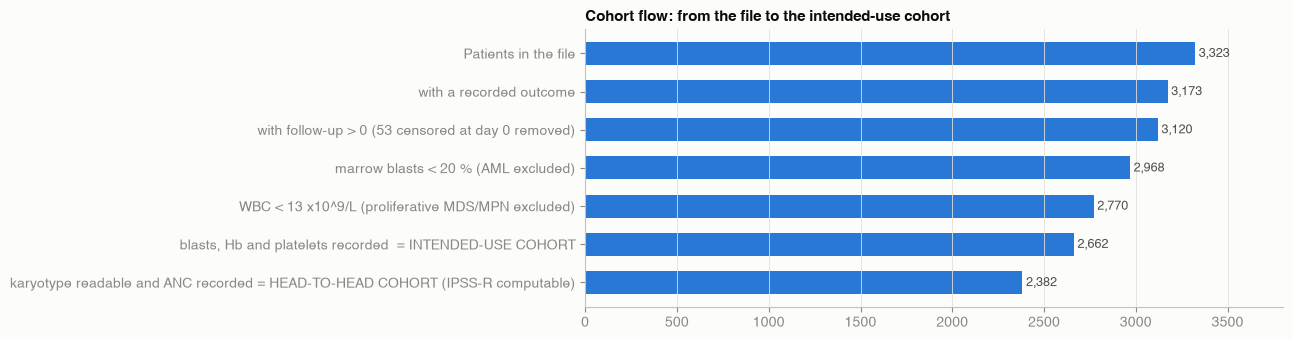

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(flow.step[::-1], flow.patients[::-1], color=plotting.SERIES[0], height=0.6)
for i, v in enumerate(flow.patients[::-1]):
    ax.text(v + 20, i, f"{v:,}", va="center", fontsize=9, color=plotting.INK2)
ax.set_xlim(0, 3800)
ax.set_title("Cohort flow: from the file to the intended-use cohort")
ax.grid(axis="y", visible=False)
plt.show()

In [9]:
d = df[masks["in_scope"]]          # intended-use cohort: 2,662 patients
h2h = df[masks["head_to_head"]]    # IPSS-R computable: 2,382 patients
print(f"intended use: {len(d)} patients, {int(d.OS_STATUS.sum())} deaths")
print(f"head-to-head: {len(h2h)} patients, {int(h2h.OS_STATUS.sum())} deaths")

intended use: 2662 patients, 1299 deaths
head-to-head: 2382 patients, 1129 deaths


## 4. Follow-up and censoring

A patient last seen alive at 9 months has an unknown 2-year status (Session 1, "when has follow-up truly ended?"). Dropping such patients or counting them as survivors both bias the answer.

In [10]:
t, e = d.OS_YEARS.values, d.OS_STATUS.values
grid = np.linspace(0, 15, 1501)
rev = metrics.km_curve(t, 1 - e, grid)                       # reverse Kaplan-Meier = follow-up
median_fu = grid[np.argmax(rev <= 0.5)]
km_2y = 1 - metrics.km_surv(t, e, H)
censored_early = int(((t < H) & (e == 0)).sum())
dead_2y = int(((t < H) & (e == 1)).sum())
known = d[(d.OS_YEARS >= H) | (d.OS_STATUS == 1)]

pd.DataFrame({"value": [
    f"{median_fu:.1f} years",
    f"{censored_early} ({censored_early / len(d):.0%})",
    f"{100 * km_2y:.1f} %",
    f"{100 * dead_2y / len(d):.1f} %",
    f"{100 * ((known.OS_YEARS < H) & (known.OS_STATUS == 1)).mean():.1f} %"]},
    index=["median follow-up (reverse Kaplan-Meier)", "censored before 2 years (status unknown)",
           "2-year mortality, Kaplan-Meier (correct)", "naive: censored counted as alive",
           "naive: censored patients dropped"])

,value
median follow-up (reverse Kaplan-Meier),3.8 years
censored before 2 years (status unknown),601 (23%)
"2-year mortality, Kaplan-Meier (correct)",36.0 %
naive: censored counted as alive,30.5 %
naive: censored patients dropped,39.4 %


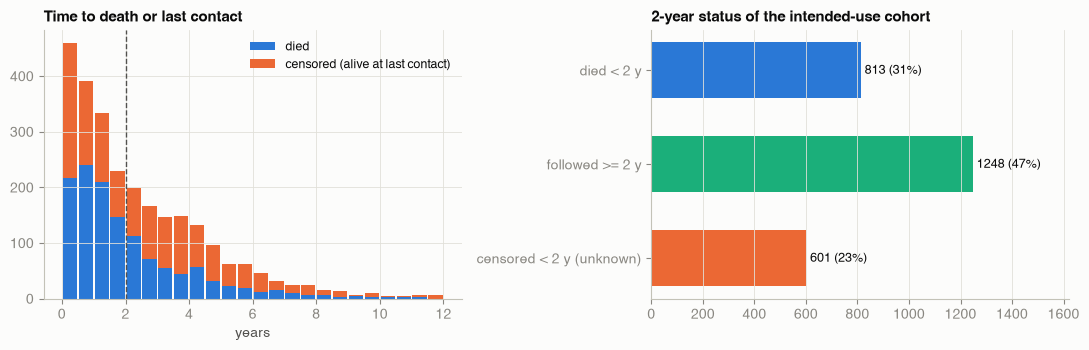

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.arange(0, 12.5, 0.5)
axes[0].hist([d.loc[d.OS_STATUS == 1, "OS_YEARS"], d.loc[d.OS_STATUS == 0, "OS_YEARS"]], bins=bins, stacked=True,
             color=[plotting.SERIES[0], plotting.SERIES[1]], rwidth=0.9, label=["died", "censored (alive at last contact)"])
axes[0].axvline(H, color=plotting.INK2, ls="--", lw=1)
axes[0].set_title("Time to death or last contact")
axes[0].set_xlabel("years")
axes[0].legend()
labels = ["died < 2 y", "followed >= 2 y", "censored < 2 y (unknown)"]
vals = [dead_2y, int((t >= H).sum()), censored_early]
axes[1].barh(labels, vals, color=[plotting.SERIES[0], plotting.SERIES[2], plotting.SERIES[1]], height=0.6)
for i, v in enumerate(vals):
    axes[1].text(v + 15, i, f"{v} ({v / len(d):.0%})", va="center", fontsize=9)
axes[1].invert_yaxis()
axes[1].set_xlim(0, max(vals) * 1.3)
axes[1].set_title("2-year status of the intended-use cohort")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
fig.savefig(f"{FIG}/F2_followup_censoring.png")
plt.show()

## 5. Missing inputs at the time of decision

In [12]:
cols = ["BM_BLAST", "HB", "PLT", "ANC", "WBC", "MONOCYTES", "CYTO_CAT"]
miss = pd.DataFrame({"all patients": df[cols].isna().mean(), "intended-use cohort": d[cols].isna().mean()})
miss = miss.rename(index={"CYTO_CAT": "karyotype missing or unreadable"})
miss.to_csv(f"{TAB}/missingness.csv")
print(f"no mutation recorded (treated as wild type): {int(d.NO_MUT_RECORDED.sum())} patients")
(100 * miss).round(1).astype(str) + " %"

no mutation recorded (treated as wild type): 244 patients


,all patients,intended-use cohort
BM_BLAST,3.3 %,0.0 %
HB,3.3 %,0.0 %
PLT,3.7 %,0.0 %
ANC,5.8 %,1.8 %
WBC,8.2 %,5.2 %
MONOCYTES,18.1 %,15.1 %
karyotype missing or unreadable,11.7 %,9.5 %


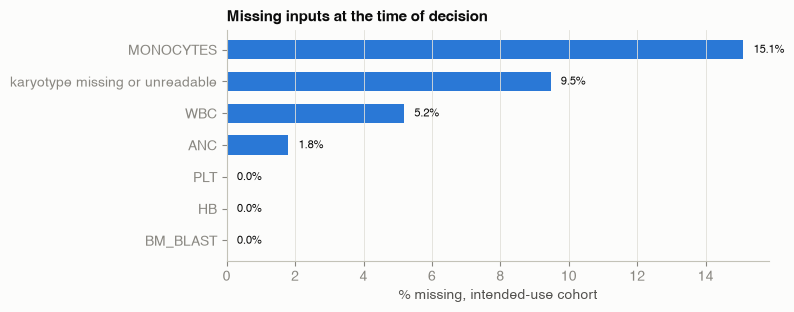

In [13]:
mm = miss["intended-use cohort"].sort_values()
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(mm.index, 100 * mm.values, color=plotting.SERIES[0], height=0.6)
for i, v in enumerate(100 * mm.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlabel("% missing, intended-use cohort")
ax.set_title("Missing inputs at the time of decision")
ax.grid(axis="y", visible=False)
fig.savefig(f"{FIG}/F4_missingness.png")
plt.show()

## 6. Centres differ more than their case mix explains

Bars: Kaplan–Meier 2-year mortality per centre. Dots: share of the centre's patients classed IPSS-M Moderate-High or worse (its case mix).

In [14]:
rows = []
for c, x in d.groupby("CENTER"):
    rows.append(dict(centre=c, patients=len(x), deaths=int(x.OS_STATUS.sum()),
                     mortality_2y=1 - metrics.km_surv(x.OS_YEARS, x.OS_STATUS, H),
                     higher_risk_share=(x.IPSSM_score > 0).mean(),
                     karyotype_missing=x.CYTO_CAT.isna().mean()))
centres = pd.DataFrame(rows).sort_values("patients", ascending=False)
centres.to_csv(f"{TAB}/centers.csv", index=False)
centres.round(3)

,centre,patients,deaths,mortality_2y,higher_risk_share,karyotype_missing
11,KI,656,386,0.371,0.463,0.069
2,DUS,383,247,0.437,0.465,0.339
14,PV,246,53,0.183,0.329,0.057
6,GESMD,227,104,0.364,0.352,0.048
16,RMCN,162,94,0.387,0.407,0.049
0,CCH,130,32,0.164,0.277,0.008
1,CGM,102,37,0.410,0.529,0.000
17,ROM,96,9,0.171,0.385,0.042
20,UOB,76,60,0.382,0.684,0.013
5,FUCE,71,37,0.423,0.563,0.268


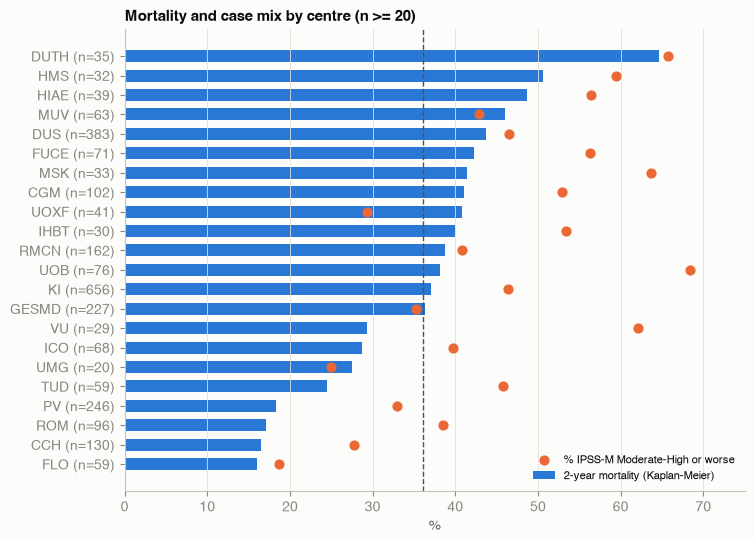

In [15]:
c2 = centres[centres.patients >= 20].sort_values("mortality_2y")
lab = [f"{c} (n={n})" for c, n in zip(c2.centre, c2.patients)]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(lab, 100 * c2.mortality_2y, color=plotting.SERIES[0], height=0.62, label="2-year mortality (Kaplan-Meier)")
ax.scatter(100 * c2.higher_risk_share, lab, color=plotting.SERIES[1], s=40, zorder=3, label="% IPSS-M Moderate-High or worse")
ax.axvline(100 * km_2y, color=plotting.INK2, ls="--", lw=1)
ax.set_xlabel("%")
ax.set_xlim(0, 75)
ax.set_title("Mortality and case mix by centre (n >= 20)")
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="y", visible=False)
fig.savefig(f"{FIG}/F3_centre_heterogeneity.png")
plt.show()

Two-year mortality runs from 16 % to 65 %. Part of it is case mix, but not all (notebook 3 quantifies the rest). This is why models are validated by holding out one centre at a time (notebook 2).

## 7. The reference scores, and the overlap with the IPSS-M cohort

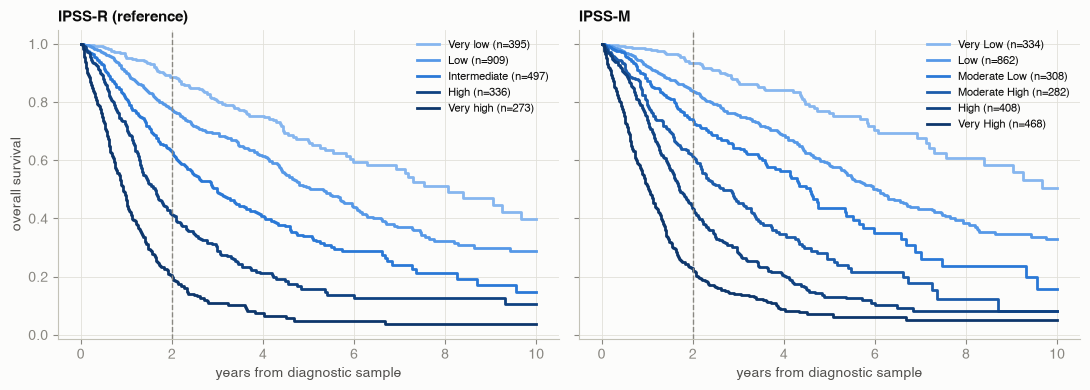

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
grid10 = np.linspace(0, 10, 501)
for ax, col, title in [(axes[0], "IPSSR_cat", "IPSS-R (reference)"), (axes[1], "IPSSM_cat", "IPSS-M")]:
    groups = [g for g in d[col].cat.categories if (d[col] == g).any()]
    for colour, g in zip(plotting.ramp(len(groups)), groups):
        x = d[d[col] == g]
        ax.step(grid10, metrics.km_curve(x.OS_YEARS, x.OS_STATUS, grid10), where="post", color=colour, label=f"{g} (n={len(x)})")
    ax.axvline(H, color=plotting.MUTED, ls="--", lw=1)
    ax.set_title(title)
    ax.set_xlabel("years from diagnostic sample")
    ax.legend(fontsize=8)
axes[0].set_ylabel("overall survival")
plt.tight_layout()
fig.savefig(f"{FIG}/F1_km_reference_scores.png")
plt.show()

In [17]:
from lifelines import KaplanMeierFitter
published = {"Very Low": 10.6, "Low": 6.0, "Moderate Low": 4.6, "Moderate High": 2.8, "High": 1.7, "Very High": 1.0}
rows = []
for g, x in d.groupby("IPSSM_cat", observed=True):
    rows.append(dict(group=g, patients=len(x),
                     median_survival_this_file=round(KaplanMeierFitter().fit(x.OS_YEARS, x.OS_STATUS).median_survival_time_, 1),
                     median_survival_published=published[g],
                     mortality_2y=round(1 - metrics.km_surv(x.OS_YEARS, x.OS_STATUS, H), 3)))
groups = pd.DataFrame(rows)
groups.to_csv(f"{TAB}/reference_groups_2y.csv", index=False)
groups

,group,patients,median_survival_this_file,median_survival_published,mortality_2y
0,Very Low,334,10.6,10.6,0.064
1,Low,862,6.0,6.0,0.164
2,Moderate Low,308,4.6,4.6,0.266
3,Moderate High,282,2.6,2.8,0.388
4,High,408,1.7,1.7,0.568
5,Very High,468,1.0,1.0,0.780


Five of the six IPSS-M group medians in this file equal the published ones (Bernard et al. 2022; American Cancer Society summary), and the entry criteria and 3.8-year median follow-up match too. **These patients very likely helped build IPSS-M**, so IPSS-M is partly judged in-sample here. Notebook 2 measures how much that matters.

## What this means for the task

- The file supports a **2-year prognosis under standard care**, not an estimate of transplant benefit.
- Censoring is substantial (23 % before 2 years): every estimate must be censoring-aware.
- About 1 in 10 patients lacks a readable karyotype: the tool must widen its uncertainty, not guess.
- Centres differ: validate by holding out centres, and expect absolute risk to need local recalibration.

→ **Notebook 2** compares IPSS-R, IPSS-M and our own models.

In [18]:
audit = dict(
    cohort_flow=steps,
    intended_use=dict(patients=len(d), deaths=int(d.OS_STATUS.sum()), median_followup_years=round(float(median_fu), 2),
                      km_death_2y=round(float(km_2y), 4), censored_before_2y=censored_early,
                      followed_2y=int((d.OS_YEARS >= H).sum()), followed_5y=int((d.OS_YEARS >= 5).sum()),
                      naive_2y_death_censored_as_alive=round(dead_2y / len(d), 4),
                      naive_2y_death_censored_dropped=round(float(((known.OS_YEARS < H) & (known.OS_STATUS == 1)).mean()), 4)),
    karyotype_missing=int(d.CYTO_CAT.isna().sum()), no_mutation_recorded=int(d.NO_MUT_RECORDED.sum()),
    centres=int(d.CENTER.nunique()),
    centre_2y_mortality_range_n20=[round(float(c2.mortality_2y.min()), 3), round(float(c2.mortality_2y.max()), 3)])
json.dump(audit, open("outputs/audit.json", "w"), indent=2)
print(json.dumps({k: v for k, v in audit.items() if k != "cohort_flow"}, indent=1))

{
 "intended_use": {
  "patients": 2662,
  "deaths": 1299,
  "median_followup_years": 3.83,
  "km_death_2y": 0.3602,
  "censored_before_2y": 601,
  "followed_2y": 1248,
  "followed_5y": 360,
  "naive_2y_death_censored_as_alive": 0.3054,
  "naive_2y_death_censored_dropped": 0.3945
 },
 "karyotype_missing": 252,
 "no_mutation_recorded": 244,
 "centres": 23,
 "centre_2y_mortality_range_n20": [
  0.16,
  0.647
 ]
}
